Name : Aishi De Sec : A Sem : 7 PRN : 23070521008 Batch : A1


AIM :
Slot Filling using Recurrent Neural Networks. Problem Statement: Implement sequence
labeling for Spoken Language Understanding using RNN/LSTM. Activities: Text
preprocessing; Train sequence labeling model; Evaluate prediction accuracy.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Sample spoken queries with corresponding IOB slot labels
sentences = [
    "book a flight from boston to new york",
    "show me flights leaving dallas tomorrow morning",
    "find cheapest flights from seattle to chicago on monday",
    "i want to fly from denver to san francisco next week",
    "show flights from atlanta to miami",
    "book tickets from new york to boston on friday",
    "find morning flights from chicago to seattle",
    "show all flights departing from san francisco to dallas",
    "list flights from miami to atlanta arriving tuesday",
    "i need a flight from boston to denver tomorrow"
] * 40  # Replicate sample distribution

slot_tags = [
    "O O O O B-fromloc.city_name O B-toloc.city_name I-toloc.city_name",
    "O O O O B-fromloc.city_name B-depart_date.today_relative B-depart_time.time_of_day",
    "O B-cost_relative O O B-fromloc.city_name O B-toloc.city_name O B-depart_date.day_name",
    "O O O O O B-fromloc.city_name O B-toloc.city_name I-toloc.city_name B-depart_date.date B-depart_date.date",
    "O O O B-fromloc.city_name O B-toloc.city_name",
    "O O O B-fromloc.city_name I-fromloc.city_name O B-toloc.city_name O B-depart_date.day_name",
    "O B-depart_time.time_of_day O O B-fromloc.city_name O B-toloc.city_name",
    "O O O O O B-fromloc.city_name I-fromloc.city_name O B-toloc.city_name",
    "O O O B-fromloc.city_name O B-toloc.city_name O B-arrive_date.day_name",
    "O O O O O B-fromloc.city_name O B-toloc.city_name B-depart_date.today_relative"
] * 40

print(f"Total dataset samples: {len(sentences)}")

Total dataset samples: 400


In [ ]:
# 1. Tokenize input words
word_tokenizer = Tokenizer(oov_token="<OOV>", lower=True)
word_tokenizer.fit_on_texts(sentences)
X_seq = word_tokenizer.texts_to_sequences(sentences)

# 2. Tokenize slot labels (reserve index 0 for padding)
tag_tokenizer = Tokenizer(lower=False, filters='')
tag_tokenizer.fit_on_texts(slot_tags)
y_seq = tag_tokenizer.texts_to_sequences(slot_tags)

# Vocabulary sizes
vocab_size = len(word_tokenizer.word_index) + 1
num_tags = len(tag_tokenizer.word_index) + 1
max_len = max(len(s.split()) for s in sentences)

# Pad sequences to uniform length
X = pad_sequences(X_seq, maxlen=max_len, padding='post')
y = pad_sequences(y_seq, maxlen=max_len, padding='post')

# One-hot encode targets for TimeDistributed Softmax
y_categorical = tf.keras.utils.to_categorical(y, num_classes=num_tags)

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42
)

print(f"Vocab size: {vocab_size} | Total Tags: {num_tags} | Max Sequence Length: {max_len}")
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")

Vocab size: 41 | Total Tags: 12 | Max Sequence Length: 11
X_train shape: (320, 11) | y_train shape: (320, 11, 12)


In [ ]:
# Build Bidirectional LSTM Architecture
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(max_len,)),
    tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(num_tags, activation='softmax'))
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 11, 64)         │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 11, 128)        │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 11, 12)         │         1,548 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,220 (274.30 KB)

 Trainable params: 70,220 (274.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6699 - loss: 1.1145 - val_accuracy: 0.8976 - val_loss: 0.4084
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9824 - loss: 0.1177 - val_accuracy: 1.0000 - val_loss: 0.0082
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 1.0000 - val_loss: 8.7202e-04
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 4.3417e-04
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 7.3525e-04 - val_accuracy: 1.0000 - val_loss: 3.2581e-04
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 5.9525e-04 - val_accuracy: 1.0000 - val_loss: 2.6188e-04
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 5.0981e-04 - val_accuracy: 1.0000 - val_loss: 2.1904e-04
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 1.0000 - loss: 4


Test Loss: 0.0001
Test Tag Accuracy: 100.00%


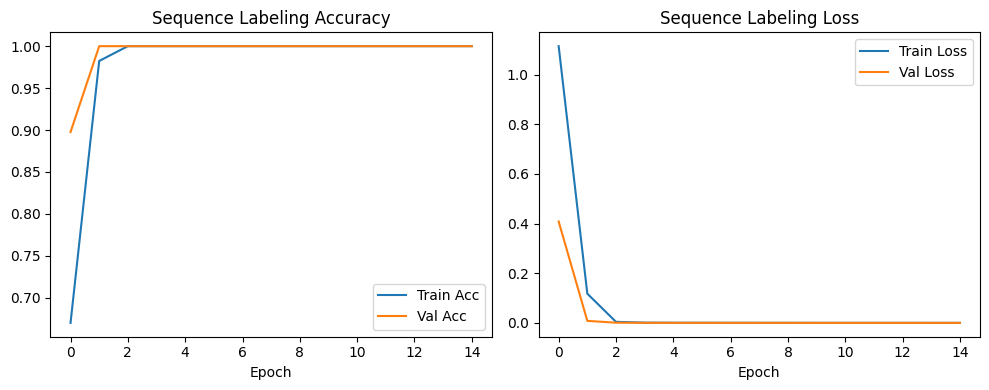

In [ ]:
import matplotlib.pyplot as plt

# Evaluate on test partition
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Tag Accuracy: {accuracy * 100:.2f}%")

# Plot training vs validation metrics
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Sequence Labeling Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Sequence Labeling Loss')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Reverse index-to-tag mapping
idx2tag = {idx: tag for tag, idx in tag_tokenizer.word_index.items()}
idx2tag[0] = "PAD"

def predict_slots(query):
    seq = word_tokenizer.texts_to_sequences([query])
    padded_seq = pad_sequences(seq, maxlen=max_len, padding='post')

    preds = model.predict(padded_seq, verbose=0)
    pred_indices = np.argmax(preds[0], axis=-1)

    tokens = query.split()
    print(f"\nInput Query: \"{query}\"")
    print(f"{'Token':<15} | {'Predicted Slot Tag'}")
    print("-" * 38)

    for token, idx in zip(tokens, pred_indices[:len(tokens)]):
        print(f"{token:<15} | {idx2tag.get(idx, 'O')}")

# Test custom queries
predict_slots("book a flight from boston to miami on monday")
predict_slots("show flights leaving dallas tomorrow morning")


Input Query: "book a flight from boston to miami on monday"
Token           | Predicted Slot Tag
--------------------------------------
book            | O
a               | O
flight          | O
from            | O
boston          | B-fromloc.city_name
to              | O
miami           | B-toloc.city_name
on              | O
monday          | B-depart_date.day_name

Input Query: "show flights leaving dallas tomorrow morning"
Token           | Predicted Slot Tag
--------------------------------------
show            | O
flights         | O
leaving         | O
dallas          | B-fromloc.city_name
tomorrow        | B-depart_date.today_relative
morning         | B-depart_time.time_of_day
